# **Multimodal RAG (PDF With Images)**

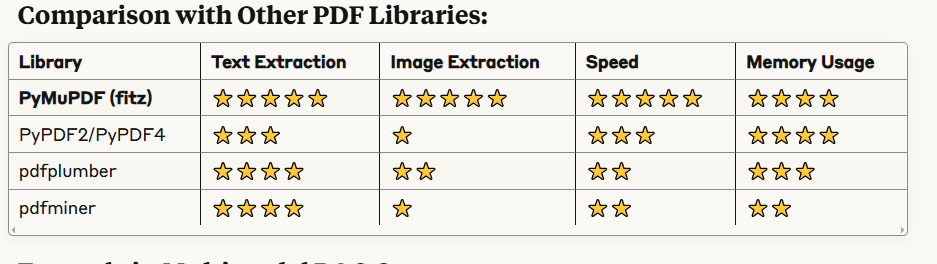

**Installing out the Required Libraries**

In [200]:
# %pip install pymupdf langchain-core transformers pillow torch numpy langchain scikit-learn langchain-community faiss-cpu

**Importing Required Libraries**

In [201]:
import os

# to load the Gemini's API Key
from dotenv import load_dotenv
load_dotenv()

from PIL import Image
import torch
import numpy as np
import pymupdf  # PyMuPDF
from sklearn.metrics.pairwise import cosine_similarity
from transformers import CLIPProcessor, CLIPModel
import base64   # to store image embeddings in base64 format
import io
from langchain_core.documents import Document
from langchain.chat_models import init_chat_model
from langchain_core.prompts import PromptTemplate
from langchain_core.messages import HumanMessage
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

**Loading out the Gemini's API Key**

In [202]:
API_KEY = os.getenv("GEMINI_API_KEY")
if not API_KEY:
    raise ValueError("Warning!!! Google Gemini's API Key is Missing")
else:
    print("Google Gemini's API Key found successfully")

Google Gemini's API Key found successfully


**Processing PDF**

In [203]:
file_path = r'C:\Users\Sheewakoti-Manish\Documents\My-Codes\Sharp-Blue-Tasks\Multimodal RAG\multimodal_sample.pdf'
doc=pymupdf.open(file_path)

# To store all Documents and Embeddings
all_docs = []
all_embeddings = []
image_data_store = {}  # Store actual image data for LLM

# Text splitter: for creating text chunks of the documents
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)

**Initializing the Clip Model for Unified Embeddings: Hypertuning Clip Model**
- **clip_model:** for extracting features from images and texts
- **clip_processor:** model le bujhiney format ma convert gardinxa
- **clip_model.eval():** Model lai evaluation mode ma rakhcha

In [204]:
clip_model=CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor=CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 16325.52it/s]


CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1

**Defining Embedding Functions for both Text and Images**

In [205]:
# Function for Embedding Text
def embed_text(text):       # Embedding Text using CLIP
    inputs = clip_processor(
        text=text, 
        return_tensors="pt", 
        padding=True,
        truncation=True,
        max_length=77  # CLIP's max token length
    )
    with torch.no_grad():
        features = clip_model.get_text_features(**inputs)
        # Extract tensor if model returns an output object
        # Trying to access 
        if hasattr(features, "pooler_output"):
            features = features.pooler_output       # accessing actual tensor using pooler_output
        # Normalize embeddings to unit vector
        features = features / features.norm(dim=-1, keepdim=True)
        # this norm is only available on tensors, 
        return features.squeeze().numpy()

In [206]:
# Function for Embedding Images
def embed_image(image_data):     # Embedding image using CLIP
    if isinstance(image_data, str):  # If path
        image = Image.open(image_data).convert("RGB")
    else:  # If PIL Image
        image = image_data
    
    inputs=clip_processor(images=image,return_tensors="pt")
    with torch.no_grad():
        features = clip_model.get_image_features(**inputs)
        # Normalize embeddings to unit vector
        features = features / features.norm(dim=-1, keepdim=True)
        return features.squeeze().numpy()

In [207]:
for i, page in enumerate(doc):
    # Firstly, processing Text
    text = page.get_text()
    # print(text)
    if text.strip():
        # Creating Temporary Document for Splitting (Creating Chunks)
        temp_doc = Document(page_content=text, metadata={"page": i, "type": text})
        print(temp_doc)
        text_chunks = splitter.split_documents([temp_doc])
        # Embedding Each Chunk using CLIP
        for chunk in text_chunks:
            embedding = embed_text(chunk.page_content)
            all_embeddings.append(embedding)
            all_docs.append(chunk)      # text chunk gayera store vaira xa

    # Then, processing Image
    # Should take three important action: 
        # - Convert Image into a PIL Format
        # - Creating Unique Identifier
        # - Store as base64 for GPT-4V (which needs base64 images)
        # - Create CLIP embedding for retrieval
    for img_index, img in enumerate(page.get_images(full = True)):
        try:
            xref = img[0]
            base_image = doc.extract_image(xref)
            # print(base_image) # properties of image: dimension, color, size, etc.
            image_bytes = base_image["image"]   # raw binary data of png file
            # print(image_bytes)

            # Converting to PIL Images
            pil_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
            # Creating Unique Identifier
            image_id = f"page_{i}_img_{img_index}"

            # Storing the Image as base64 format for later use with GPT-4V
            buffered = io.BytesIO()
            pil_image.save(buffered, format="PNG")
            img_base64 = base64.b64encode(buffered.getvalue()).decode()
            image_data_store[image_id] = img_base64

            # Embed Image using CLIP
            embedding = embed_image(pil_image)
            all_embeddings.append(embedding)

            # Create Document for Image
            image_doc = Document(
                page_content = f"[Image: {image_id}]", 
                metadata = {"page": i, 
                            "type": "image", 
                            "image_id": image_id,
                            }
                )
            all_docs.append(image_doc)

        except Exception as ex:
            print(f"Error Processing Image {img_index} on Page {i}: {ex}")
doc.close()
print(f"Successfully processed and embedded {len(all_docs)} total items (text and images)!")

page_content='Annual Revenue Overview
This document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart
below, revenue grew steadily with the highest growth recorded in Q3.
Q1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed
Q1 due to marketing campaigns. Q3 had exponential growth due to global expansion.
' metadata={'page': 0, 'type': 'Annual Revenue Overview\nThis document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart\nbelow, revenue grew steadily with the highest growth recorded in Q3.\nQ1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed\nQ1 due to marketing campaigns. Q3 had exponential growth due to global expansion.\n'}
Error Processing Image 0 on Page 0: 'BaseModelOutputWithPooling' object has no attribute 'norm'
Successfully processed and embedded 1 total items (text and images)!


In [208]:
print(all_docs[0].page_content)

Annual Revenue Overview
This document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart
below, revenue grew steadily with the highest growth recorded in Q3.
Q1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed
Q1 due to marketing campaigns. Q3 had exponential growth due to global expansion.


**Create Unified FAISS Vector Store with CLIP Embeddings**

In [209]:
embeddings_array = np.array(all_embeddings)
print("Rows: ", embeddings_array.shape[0])
print("Columns: ", embeddings_array.shape[1])

Rows:  1
Columns:  512


In [210]:
(all_docs, embeddings_array)

([Document(metadata={'page': 0, 'type': 'Annual Revenue Overview\nThis document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart\nbelow, revenue grew steadily with the highest growth recorded in Q3.\nQ1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed\nQ1 due to marketing campaigns. Q3 had exponential growth due to global expansion.\n'}, page_content='Annual Revenue Overview\nThis document summarizes the revenue trends across Q1, Q2, and Q3. As illustrated in the chart\nbelow, revenue grew steadily with the highest growth recorded in Q3.\nQ1 showed a moderate increase in revenue as new product lines were introduced. Q2 outperformed\nQ1 due to marketing campaigns. Q3 had exponential growth due to global expansion.')],
 array([[-2.67244875e-03,  1.28299864e-02, -5.18313907e-02,
          4.14879620e-02, -2.33942103e-02, -7.55868200e-03,
         -3.67659368e-02,  1.19710691e-01,  8.52080807e-02,
          2.054241

**Create Custom FAISS Index since we have precomputed embeddings**

In [211]:
text_embeddings = []
metadatas = []

for doc, emb in zip(all_docs, embeddings_array):
    text_embeddings.append((doc.page_content, emb))
    metadatas.append(doc.metadata)
# This for-loop can be written as: 
# [(doc.page_content, emb) for doc, emb in zip(all_docs, embeddings_array)]

# Storing it in vector database
vector_store = FAISS.from_embeddings(
    text_embeddings=text_embeddings, 
    embedding=None, 
    metadatas=metadatas
)

vector_store

`embedding_function` is expected to be an Embeddings object, support for passing in a function will soon be removed.


**Initializing GPT-4 Vision Model: LLM**

In [212]:
llm = init_chat_model("google_genai:gemini-3.8-flash")
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.7.7', 'langchain': '1.4.9', 'langchain-google-genai': '4.4.3'}}, profile={'name': 'Gemini 3.8 Flash', 'release_date': '2026-09-02', 'last_updated': '2026-09-02', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True}, google_api_key=SecretStr('**********'), model='gemini-3.8-flash', temperature=None, client=<google.genai.client.Client object at 0x000001B4B5308F10>, default_metadata=(), model_kwargs={})

**Unified retrieval using CLIP embeddings for both text and images.**

In [213]:
def retrieve_multimodal(query, k=5):
    # Embedding Query using CLIP
    query_embedding = embed_text(query)
    # Search in Unified Vector Store
    results = vector_store.similarity_search_by_vector(embedding=query_embedding, k=k)
    return results

**Create a message with both text and images for Gemini.**

In [214]:
def create_multimodal_message(query, retrieved_docs):
    content = []
    
    # Add the query
    content.append({
        "type": "text", 
        "text": f"Question: {query}\n\nContext:\n"})
    # Separating Image and Text Document
    text_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "text"]
    image_docs = [doc for doc in retrieved_docs if doc.metadata.get("type") == "image"]

    # Adding Text Context
    if text_docs:
        text_context = "\n\n".join(
            [
                f"[Page {doc.metadata['page']}]: {doc.page_content}]" 
                for doc in text_docs
                ])
        content.append({
            "type": "text", 
            "text": f"Text excerpts: \n{text_context}\n"
        })
    # Adding Image Content
    for doc in image_docs:
        image_id = doc.metadata.get("image_id")
        if image_id and image_id in image_data_store:
            content.append({
                "type": "text", 
                "text": f"Text excerpts: \n{text_context}\n"
            })
    # Adding out instruction 
    content.append({
        "type": "text", 
        "text": "\n\nPlease answer the question based on the provided text and images."
    })
    return HumanMessage(content = content)

In [215]:
from tenacity import (retry, stop_after_attempt, wait_exponential, retry_if_exception_type)

from google.genai.errors import ServerError, ClientError

@retry(
    retry=retry_if_exception_type(ServerError),
    wait=wait_exponential(
        multiplier=2,
        min=2,
        max=30
    ),
    stop=stop_after_attempt(5),
    reraise=True
)
def invoke_gemini(message):
    return llm.invoke(message)

**Main Pipeline for Multi-modal RAG**

In [216]:
def multimodal_pdf_rag_pipeline(query):
    # Retrieve relevant documents
    context_docs = retrieve_multimodal(query, k=5)
    
    # Create multimodal message
    message = create_multimodal_message(query, context_docs)
    
    # Get response from Gemini
    response = invoke_gemini([message])
    
    # Print retrieved context info
    print(f"\nRetrieved {len(context_docs)} documents:")
    for doc in context_docs:
        doc_type = doc.metadata.get("type", "unknown")
        page = doc.metadata.get("page", "?")
        if doc_type == "text":
            preview = doc.page_content[:100] + "..." if len(doc.page_content) > 100 else doc.page_content
            print(f"  - Text from page {page}: {preview}")
        else:
            print(f"  - Image from page {page}")
    print("\n")
    
    return response.content

In [217]:
if __name__ == "__main__":
    # Example queries
    queries = [
        "What does the chart on page 1 show about revenue trends?",
        "Summarize the main findings from the document",
        "What visual elements are present in the document?"
    ]
    
    for query in queries:
        print(f"\nQuery: {query}")
        print("-" * 50)
        answer = multimodal_pdf_rag_pipeline(query)
        print(f"Answer: {answer}")
        print("=" * 70)


Query: What does the chart on page 1 show about revenue trends?
--------------------------------------------------


GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 17h31m48.337337619s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate conte